# Task 3 — Dimensionamiento y robustez


Parámetros del grupo: $\lambda=3.6$ pac./día, $\mu=0.25$/día, estancia media 4 días, 17 camas actuales, $k_{off}=6$, cierre de 7 días. Metas: $P_{bloqueo}\le 0.02$ y $W_q\le 6$ h. Unidad interna: días; esperas reportadas también en horas.


## Preparación del simulador

Se conservan heapq, cola FCFS, promedios ponderados por tiempo y seguimiento completo de pacientes medidos. Como en Task 2: distribución de estancia, streams separados y cierre no preemptivo (no se expulsan ocupantes; solo se impiden nuevos ingresos por encima de la capacidad reducida).

**Modificación mínima (Task 3.1c):** si hay `closure=(t0, Tb, k_off)`, se cuentan `arrivals_closure` y `blocked_closure` únicamente para llegadas en $[t_0, t_0+T_b)$. Opcionalmente se acumula ocupación diaria en ese intervalo.


In [1]:
"""Extensión del motor de Task2 / task_1_3_corregido.py para Task 3 (sin tocar originales)."""
import heapq
import math
import os
import random
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

OUT = Path('outputs/task3')
OUT.mkdir(parents=True, exist_ok=True)
Path('figuras').mkdir(exist_ok=True)

# Parámetros del grupo 4
G = 4
LAM = 3.6
MU = 0.25
C_ACTUAL = 17
K_OFF = 6
T_CIERRE = 7.0
META_BLOQUEO = 0.02
META_WQ_DIAS = 6 / 24
META_WQ_HORAS = 6.0
N_REP = 30
HORIZON = 3000
WARMUP = 100
CONF = 0.95
MASTER = 340310  # semilla maestra Task 3


def erlang_b(c, a):
    b = 1.0
    for j in range(1, int(c) + 1):
        b = a * b / (j + a * b)
    return b


def erlang_c_wq(lam, mu, c):
    """P(esperar), Lq y Wq (días/horas). Si inestable, Wq = inf."""
    a = lam / mu
    if lam >= c * mu:
        return dict(C=float('inf'), Lq=float('inf'), Wq_days=float('inf'),
                    Wq_hours=float('inf'), B=erlang_b(c, a), rho=a / c if c else float('inf'))
    rho = a / c
    B = erlang_b(c, a)
    C = B / (1 - rho + rho * B)
    Lq = C * rho / (1 - rho)
    Wq = Lq / lam
    return dict(C=C, Lq=Lq, Wq_days=Wq, Wq_hours=24 * Wq, B=B, rho=rho)


def lognormal_params(mean=4.0, Cs=2.0):
    sigma2 = math.log(1 + Cs ** 2)
    sigma = math.sqrt(sigma2)
    m = math.log(mean) - sigma2 / 2
    return m, sigma, sigma2


def simulate_hospital(lam, mu, c, horizon, warmup, seed, waiting=True,
                      distribution='exponencial', sample_every=None,
                      closure=None, split_streams=True, interarrival=None,
                      fixed_service=None, Cs=2.0):
    """Réplica DES. Igual a Task 2 + contadores de cierre y ocupación diaria en cierre."""
    if not (lam > 0 and mu > 0 and c >= 1 and 0 <= warmup < horizon):
        raise ValueError('Parámetros inválidos.')
    if distribution not in ('determinista', 'exponencial', 'lognormal'):
        raise ValueError('Distribución desconocida.')
    if closure:
        t0, Tb, koff = closure
        if not (0 < koff <= c and Tb > 0 and t0 + Tb <= horizon):
            raise ValueError('Cierre inválido.')
    if split_streams:
        master = random.Random(seed)
        rng_arr = random.Random(master.getrandbits(128))
        rng_srv = random.Random(master.getrandbits(128))
    else:
        rng_arr = rng_srv = random.Random(seed)

    mean_service = 1 / mu
    m_ln, s_ln, _ = lognormal_params(mean_service, Cs)

    def arrival_time():
        return interarrival if interarrival is not None else rng_arr.expovariate(lam)

    def service_time():
        if fixed_service is not None:
            return fixed_service
        if distribution == 'determinista':
            return mean_service
        if distribution == 'lognormal':
            return rng_srv.lognormvariate(m_ln, s_ln)
        return rng_srv.expovariate(mu)

    events, queue, samples = [], deque(), []
    counter = 0

    def schedule(t, kind, info=None):
        nonlocal counter
        heapq.heappush(events, (t, counter, kind, info))
        counter += 1

    schedule(arrival_time(), 'arrival')
    if closure:
        t0, Tb, koff = closure
        schedule(t0, 'close')
        schedule(t0 + Tb, 'open')
    else:
        t0 = Tb = koff = None

    capacity = c
    busy = arrivals = admitted = blocked = waited = wait_count = sojourn_count = 0
    wait_sum = sojourn_sum = area_system = area_queue = area_busy = area_capacity = 0.0
    arrivals_closure = blocked_closure = 0
    daily_occ = {}  # día relativo al cierre -> suma ocupación * dt / dt total simplificado
    daily_arr = {}
    daily_blk = {}
    t_prev = next_sample = 0.0

    def start(t, patient):
        nonlocal busy, wait_count, wait_sum
        busy += 1
        if patient[1]:
            wait_count += 1
            wait_sum += t - patient[0]
        schedule(t + service_time(), 'departure', patient)

    def fill(t):
        while queue and busy < capacity:
            start(t, queue.popleft())

    def in_closure_window(t):
        return closure is not None and t0 <= t < t0 + Tb

    while events:
        t, _, kind, info = heapq.heappop(events)
        end, left = min(t, horizon), max(t_prev, warmup)
        if end > left:
            dt = end - left
            area_system += (busy + len(queue)) * dt
            area_queue += len(queue) * dt
            area_busy += busy * dt
            area_capacity += capacity * dt
        # ocupación diaria durante el cierre (incluye tramos previos al warmup si caen ahí)
        if closure and end > t_prev:
            seg_lo, seg_hi = max(t_prev, t0), min(end, t0 + Tb)
            if seg_hi > seg_lo:
                # repartir por días enteros relativos
                u = seg_lo
                while u < seg_hi - 1e-12:
                    day = int(math.floor(u - t0))
                    day_end = t0 + day + 1
                    v = min(seg_hi, day_end)
                    daily_occ[day] = daily_occ.get(day, 0.0) + busy * (v - u)
                    u = v
        if sample_every is not None:
            while next_sample <= end + 1e-10:
                samples.append((next_sample, len(queue), busy + len(queue), capacity, busy))
                next_sample += sample_every
        t_prev = end

        if kind == 'arrival':
            if t >= horizon:
                continue
            schedule(t + arrival_time(), 'arrival')
            measured = t >= warmup
            patient = (t, measured)
            arrivals += int(measured)
            if in_closure_window(t):
                arrivals_closure += 1
                day = int(math.floor(t - t0))
                daily_arr[day] = daily_arr.get(day, 0) + 1
            if busy < capacity:
                admitted += int(measured)
                start(t, patient)
            elif waiting:
                queue.append(patient)
                waited += int(measured)
                admitted += int(measured)
            else:
                blocked += int(measured)
                if in_closure_window(t):
                    blocked_closure += 1
                    day = int(math.floor(t - t0))
                    daily_blk[day] = daily_blk.get(day, 0) + 1
        elif kind == 'departure':
            if info[1]:
                sojourn_sum += t - info[0]
                sojourn_count += 1
            busy -= 1
            fill(t)
        elif kind == 'close':
            capacity = c - koff
        elif kind == 'open':
            capacity = c
            fill(t)

    observed = horizon - warmup
    out = dict(
        L=area_system / observed, Lq=area_queue / observed,
        Wq_hours=24 * wait_sum / wait_count if wait_count else float('nan'),
        Wq_days=wait_sum / wait_count if wait_count else float('nan'),
        W_hours=24 * sojourn_sum / sojourn_count if sojourn_count else float('nan'),
        utilization=area_busy / area_capacity if area_capacity else float('nan'),
        prob_wait=waited / arrivals if arrivals else float('nan'),
        prob_block=blocked / arrivals if arrivals else float('nan'),
        lambda_ef=admitted / observed,
        arrivals=arrivals, admitted=admitted, blocked=blocked,
        arrivals_closure=arrivals_closure, blocked_closure=blocked_closure,
        prob_block_closure=(blocked_closure / arrivals_closure
                           if arrivals_closure else float('nan')),
        daily_occ=daily_occ, daily_arr=daily_arr, daily_blk=daily_blk,
    )
    if sample_every is not None:
        out['trayectoria'] = np.asarray(samples)
    return out


def replica_seeds(n, master_seed):
    """Semillas independientes vía SeedSequence (reproducible)."""
    ss = np.random.SeedSequence(master_seed)
    children = ss.spawn(n)
    return [int(c.generate_state(1)[0]) for c in children]


def ic95(xs):
    xs = np.asarray(xs, dtype=float)
    xs = xs[np.isfinite(xs)]
    if len(xs) < 2:
        raise ValueError('El IC requiere al menos dos réplicas finitas.')
    avg = float(xs.mean())
    s = float(xs.std(ddof=1))
    half = float(stats.t.ppf(0.975, len(xs) - 1) * s / math.sqrt(len(xs)))
    return dict(media=avg, std=s, semiancho=half, inferior=avg - half, superior=avg + half,
                n=len(xs))


def replicas(n, master_seed, **kwargs):
    return [simulate_hospital(seed=s, **kwargs) for s in replica_seeds(n, master_seed)]


def veredicto_vs_meta(ic, meta, menor_mejor=True):
    """cumple / no cumple / inconcluso según IC 95 % vs umbral."""
    if menor_mejor:
        if ic['superior'] <= meta:
            return 'cumple'
        if ic['inferior'] > meta:
            return 'no cumple'
        return 'inconcluso'
    if ic['inferior'] >= meta:
        return 'cumple'
    if ic['superior'] < meta:
        return 'no cumple'
    return 'inconcluso'


def min_c_erlang_b(lam, mu, meta=META_BLOQUEO, cmax=80):
    a = lam / mu
    for c in range(1, cmax + 1):
        if erlang_b(c, a) <= meta:
            return c
    raise RuntimeError('No se halló c para Erlang B')


def min_c_erlang_c(lam, mu, meta_wq_dias=META_WQ_DIAS, cmax=80):
    for c in range(1, cmax + 1):
        if erlang_c_wq(lam, mu, c)['Wq_days'] <= meta_wq_dias:
            return c
    raise RuntimeError('No se halló c para Erlang C')


assert abs(LAM - (3.0 + 0.2 * ((G - 1) % 5))) < 1e-12
assert abs(MU - 0.25) < 1e-12
assert C_ACTUAL == 17
m_ln, s_ln, s2 = lognormal_params(4.0, 2.0)
assert abs(s2 - math.log(5)) < 1e-12
assert abs(m_ln - (math.log(4) - s2 / 2)) < 1e-12
print('Parámetros OK. Salida:', OUT.resolve())
print(f'Lognormal: m={m_ln:.6f}, sigma={s_ln:.6f}')


Parámetros OK. Salida: /home/cisco/universidad/cuarto/segundo_semestre/modelacion_sim/hdt7/HT7-MS/outputs/task3
Lognormal: m=0.581575, sigma=1.268636


## Pruebas rápidas del motor (respuesta conocida + lognormal)

In [2]:
# 1) D/D/1 sin fila
r = simulate_hospital(1/3, 1, 1, 300, 3, 7, interarrival=3, fixed_service=1)
assert abs(r['L'] - 1/3) < 1e-12 and r['Wq_hours'] == 0
print('PASA: D/D/1 sin fila.')

# 2) Cierre no preemptivo (como Task 2)
r = simulate_hospital(1, 1/3, 2, 6.1, 0, 7, closure=(4, 2, 1),
                      interarrival=1, fixed_service=3)
assert abs(r['Wq_hours']/24 - 10/6) < 1e-12
print('PASA: cierre no preemptivo.')

# 3) Contadores solo en ventana de cierre (sistema con pérdida)
# Capacidad 1, cierra a 0 en [10,12): toda llegada en ese intervalo se bloquea.
r = simulate_hospital(2, 1, 2, 20, 0, 11, waiting=False, closure=(10, 2, 2),
                      interarrival=0.5, fixed_service=0.1)
assert r['arrivals_closure'] > 0
assert r['blocked_closure'] == r['arrivals_closure']
assert abs(r['prob_block_closure'] - 1.0) < 1e-12
print('PASA: bloqueo medido solo durante el cierre.')

# 4) Muestreo lognormal: media ≈ 4, Cs ≈ 2
rng = np.random.default_rng(123)
m, s, _ = lognormal_params(4, 2)
muestra = rng.lognormal(m, s, 200_000)
media_m = float(muestra.mean())
cs_m = float(muestra.std(ddof=1) / media_m)
assert abs(media_m - 4) < 0.05
assert abs(cs_m - 2) < 0.05
print(f'PASA: lognormal muestra media={media_m:.3f}, Cs={cs_m:.3f}')

assert len(set(replica_seeds(200, MASTER))) == 200
print('PASA: semillas distintas.')


PASA: D/D/1 sin fila.
PASA: cierre no preemptivo.
PASA: bloqueo medido solo durante el cierre.
PASA: lognormal muestra media=3.991, Cs=1.971
PASA: semillas distintas.


## Parte A — Dimensionamiento teórico (Task 3.1a)

Se enumeran capacidades $c=1,2,\ldots$ hasta el menor entero que cumple cada meta. Se muestran también $c_{\min}-1$ y $c_{\min}$ para probar minimalidad. Luego se validan por simulación M/M/c (con espera) y M/M/c/c (sin espera).


In [3]:
def tabla_teorica_escenario(nombre, lam, mu):
    a = lam / mu
    cB = min_c_erlang_b(lam, mu)
    cC = min_c_erlang_c(lam, mu)
    filas = []
    for variante, cmin, meta, tipo in [
        ('sin espera', cB, META_BLOQUEO, 'B'),
        ('con espera', cC, META_WQ_HORAS, 'C'),
    ]:
        for c in (cmin - 1, cmin):
            if tipo == 'B':
                val = erlang_b(c, a)
                cumple = val <= META_BLOQUEO
                filas.append(dict(
                    escenario=nombre, variante=variante, camas=c,
                    metrica='Erlang B (bloqueo)', valor=val,
                    valor_horas_o_pct=100 * val, objetivo=META_BLOQUEO,
                    objetivo_display='≤ 2 %', cumple=cumple,
                    adicionales=c - C_ACTUAL, es_minimo=(c == cmin and cumple),
                ))
            else:
                m = erlang_c_wq(lam, mu, c)
                val_h = m['Wq_hours']
                cumple = val_h <= META_WQ_HORAS
                filas.append(dict(
                    escenario=nombre, variante=variante, camas=c,
                    metrica='Wq teórico (h)', valor=m['Wq_days'],
                    valor_horas_o_pct=val_h, objetivo=META_WQ_HORAS,
                    objetivo_display='≤ 6 h', cumple=cumple,
                    adicionales=c - C_ACTUAL, es_minimo=(c == cmin and cumple),
                ))
    return cB, cC, pd.DataFrame(filas)


cB_base, cC_base, df_teo_base = tabla_teorica_escenario('base', LAM, MU)
assert cB_base == 22 and cC_base == 19
assert not df_teo_base.query("variante=='sin espera' and camas==21")['cumple'].iloc[0]
assert df_teo_base.query("variante=='sin espera' and camas==22")['cumple'].iloc[0]
assert not df_teo_base.query("variante=='con espera' and camas==18")['cumple'].iloc[0]
assert df_teo_base.query("variante=='con espera' and camas==19")['cumple'].iloc[0]

print(f'Caso base: c_min sin espera = {cB_base} (+{cB_base-C_ACTUAL}); '
      f'c_min con espera = {cC_base} (+{cC_base-C_ACTUAL})')
display(df_teo_base[['variante', 'camas', 'metrica', 'valor_horas_o_pct',
                     'objetivo_display', 'cumple', 'adicionales']])


Caso base: c_min sin espera = 22 (+5); c_min con espera = 19 (+2)


,variante,camas,metrica,valor_horas_o_pct,objetivo_display,cumple,adicionales
0,sin espera,21,Erlang B (bloqueo),2.398387,≤ 2 %,False,4
1,sin espera,22,Erlang B (bloqueo),1.545590,≤ 2 %,True,5
2,con espera,18,Wq teórico (h),7.438941,≤ 6 h,False,1
3,con espera,19,Wq teórico (h),3.830790,≤ 6 h,True,2


### Simulación de las capacidades mínimas (y las inmediatamente inferiores)

Réplicas: 30; horizonte 3000 días; calentamiento 100 días. Métrica sin espera: `blocked/arrivals` por réplica. Con espera: `Wq` sobre todos los pacientes medidos (incluye espera 0).


In [4]:
def simular_capacidad(lam, mu, c, waiting, master_seed, n=N_REP,
                      horizon=HORIZON, warmup=WARMUP, distribution='exponencial',
                      Cs=2.0):
    rr = replicas(n, master_seed, lam=lam, mu=mu, c=c, horizon=horizon,
                  warmup=warmup, waiting=waiting, distribution=distribution, Cs=Cs)
    if waiting:
        xs = [x['Wq_hours'] for x in rr]
        meta = META_WQ_HORAS
        nombre = 'Wq (h)'
    else:
        xs = [x['prob_block'] for x in rr]
        meta = META_BLOQUEO
        nombre = 'P_bloqueo'
    ic = ic95(xs)
    verd = veredicto_vs_meta(ic, meta, menor_mejor=True)
    return dict(ic=ic, veredicto=verd, metrica=nombre, meta=meta, raw=xs, corridas=rr)


def simular_par_minimo(lam, mu, c_min, waiting, seed0, etiqueta, **kw):
    filas = []
    detalles = {}
    for c in (c_min - 1, c_min):
        print(f'  Simulando {etiqueta}: c={c}, waiting={waiting} ...', flush=True)
        res = simular_capacidad(lam, mu, c, waiting, seed0 + c, **kw)
        ic = res['ic']
        filas.append(dict(
            variante='con espera' if waiting else 'sin espera',
            camas=c,
            estimacion=ic['media'],
            std=ic['std'],
            IC95_inferior=ic['inferior'],
            IC95_superior=ic['superior'],
            semiancho=ic['semiancho'],
            objetivo=res['meta'],
            veredicto=res['veredicto'],
            n_replicas=ic['n'],
        ))
        detalles[c] = res
    return pd.DataFrame(filas), detalles


print('Parte A — simulación base')
df_sim_sin, det_sin = simular_par_minimo(LAM, MU, cB_base, False, MASTER + 1000, 'sin espera')
df_sim_con, det_con = simular_par_minimo(LAM, MU, cC_base, True, MASTER + 2000, 'con espera')
df_sim_A = pd.concat([df_sim_sin, df_sim_con], ignore_index=True)

# Tabla teórica limpia para CSV
filas_dim = []
for _, row in df_teo_base.iterrows():
    filas_dim.append(dict(
        tipo='teorico', variante=row['variante'], camas=row['camas'],
        metrica=row['metrica'], estimacion=row['valor_horas_o_pct'],
        IC95_inferior='', IC95_superior='', semiancho='',
        objetivo=row['objetivo_display'], cumple=row['cumple'],
        adicionales=row['adicionales'],
    ))
for _, row in df_sim_A.iterrows():
    if row['variante'] == 'sin espera':
        est, lo, hi, semi = (100 * row['estimacion'], 100 * row['IC95_inferior'],
                             100 * row['IC95_superior'], 100 * row['semiancho'])
        obj = '≤ 2 %'
    else:
        est, lo, hi, semi = (row['estimacion'], row['IC95_inferior'],
                             row['IC95_superior'], row['semiancho'])
        obj = '≤ 6 h'
    filas_dim.append(dict(
        tipo='simulado', variante=row['variante'], camas=int(row['camas']),
        metrica='P_bloqueo (%)' if row['variante'] == 'sin espera' else 'Wq (h)',
        estimacion=est, IC95_inferior=lo, IC95_superior=hi, semiancho=semi,
        objetivo=obj, cumple=row['veredicto'], adicionales=int(row['camas']) - C_ACTUAL,
    ))

df_dim = pd.DataFrame(filas_dim)
df_dim.to_csv(OUT / 'task3_dimensionamiento.csv', index=False)
print('Guardado:', OUT / 'task3_dimensionamiento.csv')

print('\nTabla teórica (valor en % bloqueo o horas de Wq):')
display(df_teo_base[['variante', 'camas', 'valor_horas_o_pct', 'objetivo_display', 'cumple', 'adicionales']])
print('\nTabla simulada:')
display(df_sim_A)


Parte A — simulación base
  Simulando sin espera: c=21, waiting=False ...


  Simulando sin espera: c=22, waiting=False ...


  Simulando con espera: c=18, waiting=True ...


  Simulando con espera: c=19, waiting=True ...


Guardado: outputs/task3/task3_dimensionamiento.csv

Tabla teórica (valor en % bloqueo o horas de Wq):


,variante,camas,valor_horas_o_pct,objetivo_display,cumple,adicionales
0,sin espera,21,2.398387,≤ 2 %,False,4
1,sin espera,22,1.545590,≤ 2 %,True,5
2,con espera,18,7.438941,≤ 6 h,False,1
3,con espera,19,3.830790,≤ 6 h,True,2



Tabla simulada:


,variante,camas,estimacion,std,IC95_inferior,IC95_superior,semiancho,objetivo,veredicto,n_replicas
0,sin espera,21,0.023838,0.003753,0.022436,0.025239,0.001402,0.02,no cumple,30
1,sin espera,22,0.015932,0.002402,0.015036,0.016829,0.000897,0.02,cumple,30
2,con espera,18,7.313213,1.515704,6.747240,7.879186,0.565973,6.00,no cumple,30
3,con espera,19,3.548195,0.858842,3.227498,3.868892,0.320697,6.00,cumple,30


## Parte B — Robustez ante tres escenarios (Task 3.1b)

Escenarios: (i) estancia +25 % ($\mu=0.20$), (ii) llegadas +15 % ($\lambda=4.14$), (iii) estancia lognormal con media 4 y $C_S=2$.

En (i)–(ii) se usan Erlang B/C y se validan por simulación. En (iii), sin espera se invoca la **insensibilidad** de M/G/c/c (mismo bloqueo teórico que M/M/c/c); con espera se barre por simulación M/G/c (Erlang C solo como referencia aproximada Allen–Cunneen, no exacta).


In [5]:
escenarios = {
    'base': dict(lam=LAM, mu=MU, mean_s=4.0, Cs=1.0, dist='exponencial'),
    'estancia_+25%': dict(lam=LAM, mu=0.20, mean_s=5.0, Cs=1.0, dist='exponencial'),
    'llegadas_+15%': dict(lam=4.14, mu=MU, mean_s=4.0, Cs=1.0, dist='exponencial'),
    'Cs=2_lognormal': dict(lam=LAM, mu=MU, mean_s=4.0, Cs=2.0, dist='lognormal'),
}

# Capacidades teóricas (exponencial) por escenario
caps = {}
for nombre, p in escenarios.items():
    if p['dist'] == 'exponencial':
        caps[nombre] = dict(
            sin=min_c_erlang_b(p['lam'], p['mu']),
            con=min_c_erlang_c(p['lam'], p['mu']),
        )
    else:
        # sin espera: misma c que base por insensibilidad (misma media)
        caps[nombre] = dict(sin=caps['base']['sin'], con=None)

print('Capacidades teóricas (Erlang) / referencia:')
for k, v in caps.items():
    print(f'  {k}: sin espera={v["sin"]}, con espera={v["con"]}')

filas_rob = []
candidatos_ln = []
seed_cursor = MASTER + 5000

# --- Escenarios exponenciales: teoría + simulación de mínimos ---
for nombre in ['base', 'estancia_+25%', 'llegadas_+15%']:
    p = escenarios[nombre]
    a = p['lam'] / p['mu']
    for variante, key, waiting in [('sin espera', 'sin', False), ('con espera', 'con', True)]:
        cmin = caps[nombre][key]
        teo_val = erlang_b(cmin, a) if not waiting else erlang_c_wq(p['lam'], p['mu'], cmin)['Wq_hours']
        meta = META_BLOQUEO if not waiting else META_WQ_HORAS
        print(f'{nombre} / {variante}: c_min teórico={cmin}', flush=True)
        res = simular_capacidad(p['lam'], p['mu'], cmin, waiting, seed_cursor,
                                distribution='exponencial')
        seed_cursor += 17
        ic = res['ic']
        filas_rob.append(dict(
            escenario=nombre, variante=variante, llegadas=p['lam'],
            estancia_media=p['mean_s'], Cs=p['Cs'], distribucion=p['dist'],
            camas_minimas=cmin, camas_adicionales_sobre_17=cmin - C_ACTUAL,
            metrica_meta='P_bloqueo' if not waiting else 'Wq_horas',
            meta=meta,
            estimacion_teorica_o_simulada=ic['media'],
            teorico=teo_val,
            IC95_inferior=ic['inferior'], IC95_superior=ic['superior'],
            metodo='Erlang + simulación M/M',
            veredicto=res['veredicto'],
        ))

# --- Escenario (iii) lognormal ---
# Sin espera: teoría = Erlang B (insensibilidad); simular c_min y c_min-1
cB_ln = caps['Cs=2_lognormal']['sin']
print('\\nLognormal sin espera (insensibilidad M/G/c/c):')
for c in (cB_ln - 1, cB_ln):
    # horizonte ampliado si hace falta; primero 3000/100
    print(f'  bloqueo c={c} ...', flush=True)
    res = simular_capacidad(LAM, MU, c, False, seed_cursor, distribution='lognormal', Cs=2.0)
    seed_cursor += 17
    # Si IC muy ancho cerca del umbral, reforzar
    if res['veredicto'] == 'inconcluso' or res['ic']['semiancho'] > 0.005:
        print(f'    IC amplio (semi={res["ic"]["semiancho"]:.4f}); horizonte 15000/1000', flush=True)
        res = simular_capacidad(LAM, MU, c, False, seed_cursor,
                                horizon=15000, warmup=1000, distribution='lognormal', Cs=2.0)
        seed_cursor += 17
        metodo = 'Erlang B (insensibilidad) + sim M/G/c/c (15000 d)'
    else:
        metodo = 'Erlang B (insensibilidad) + sim M/G/c/c (3000 d)'
    ic = res['ic']
    teo = erlang_b(c, LAM / MU)
    verd = res['veredicto']
    candidatos_ln.append(dict(
        tipo='bloqueo', camas=c, Wq_o_bloqueo=ic['media'],
        IC95_inferior=ic['inferior'], IC95_superior=ic['superior'],
        teorico_erlang_b=teo, veredicto=verd, metodo=metodo,
    ))
    if c == cB_ln:
        filas_rob.append(dict(
            escenario='Cs=2_lognormal', variante='sin espera', llegadas=LAM,
            estancia_media=4.0, Cs=2.0, distribucion='lognormal',
            camas_minimas=c, camas_adicionales_sobre_17=c - C_ACTUAL,
            metrica_meta='P_bloqueo', meta=META_BLOQUEO,
            estimacion_teorica_o_simulada=ic['media'], teorico=teo,
            IC95_inferior=ic['inferior'], IC95_superior=ic['superior'],
            metodo=metodo, veredicto=verd,
        ))

# Con espera lognormal: barrido por simulación (no Erlang C exacto)
# Allen–Cunneen como referencia: factor (1+Cs^2)/2 = 2.5 sobre Wq M/M
print('\\nLognormal con espera: barrido de capacidades')
# Empezar cerca de la predicción Allen–Cunneen y del mínimo M/M
c_mm = caps['base']['con']
# Buscar c tal que 2.5 * Wq_MM(c) ~ 6 h como pista
c_ac = None
for c in range(c_mm, 40):
    w = erlang_c_wq(LAM, MU, c)['Wq_hours']
    if 2.5 * w <= META_WQ_HORAS:
        c_ac = c
        break
print(f'  Referencia Allen–Cunneen (aprox.): c≈{c_ac} '
      f'(Wq_MM×2.5 = {2.5*erlang_c_wq(LAM,MU,c_ac)["Wq_hours"]:.3f} h)')

# Barrer desde max(c_mm, c_ac-3) hacia arriba hasta encontrar el mínimo verificado
c_lo = max(c_mm, (c_ac or c_mm) - 3)
c_hi = (c_ac or c_mm) + 6
mejor_con = None
for c in range(c_lo, c_hi + 1):
    print(f'  Wq lognormal c={c} (piloto 3000/100)...', flush=True)
    res = simular_capacidad(LAM, MU, c, True, seed_cursor, distribution='lognormal', Cs=2.0)
    seed_cursor += 17
    # Reforzar cerca del umbral (horizonte largo y, si sigue inconcluso, más réplicas)
    if res['veredicto'] == 'inconcluso' or abs(res['ic']['media'] - META_WQ_HORAS) < 2:
        print(f'    reforzar 15000/1000, 30 réplicas ...', flush=True)
        res = simular_capacidad(LAM, MU, c, True, seed_cursor,
                                horizon=15000, warmup=1000, distribution='lognormal', Cs=2.0)
        seed_cursor += 17
        metodo = 'simulación M/G/c (15000 d, 30 rep); AC solo referencia'
        if res['veredicto'] == 'inconcluso':
            print(f'    aún inconcluso: 60 réplicas ...', flush=True)
            res = simular_capacidad(LAM, MU, c, True, seed_cursor, n=60,
                                    horizon=15000, warmup=1000, distribution='lognormal', Cs=2.0)
            seed_cursor += 17
            metodo = 'simulación M/G/c (15000 d, 60 rep); AC solo referencia'
    else:
        metodo = 'simulación M/G/c (3000 d); AC solo referencia'
    ic = res['ic']
    w_mm = erlang_c_wq(LAM, MU, c)['Wq_hours']
    ac = 2.5 * w_mm
    candidatos_ln.append(dict(
        tipo='espera', camas=c, Wq_o_bloqueo=ic['media'],
        IC95_inferior=ic['inferior'], IC95_superior=ic['superior'],
        teorico_erlang_c_h=w_mm, allen_cunneen_h=ac,
        veredicto=res['veredicto'], metodo=metodo,
    ))
    if res['veredicto'] == 'cumple' and mejor_con is None:
        # verificar que c-1 no cumple (idealmente)
        mejor_con = c

# Confirmar minimalidad: si mejor_con tiene c-1 no explorado, explorarlo
if mejor_con is None:
    # tomar el menor con IC_superior <= 6, o marcar inconcluso el mejor intento
    cumplidores = [r for r in candidatos_ln if r['tipo'] == 'espera' and r['veredicto'] == 'cumple']
    if cumplidores:
        mejor_con = min(r['camas'] for r in cumplidores)
    else:
        # ampliar barrido
        for c in range(c_hi + 1, c_hi + 8):
            print(f'  Wq lognormal c={c} (15000/1000)...', flush=True)
            res = simular_capacidad(LAM, MU, c, True, seed_cursor,
                                    horizon=15000, warmup=1000, distribution='lognormal', Cs=2.0)
            seed_cursor += 17
            ic = res['ic']
            w_mm = erlang_c_wq(LAM, MU, c)['Wq_hours']
            candidatos_ln.append(dict(
                tipo='espera', camas=c, Wq_o_bloqueo=ic['media'],
                IC95_inferior=ic['inferior'], IC95_superior=ic['superior'],
                teorico_erlang_c_h=w_mm, allen_cunneen_h=2.5 * w_mm,
                veredicto=res['veredicto'], metodo='simulación M/G/c (15000 d)',
            ))
            if res['veredicto'] == 'cumple':
                mejor_con = c
                break

if mejor_con is not None:
    # comprobar c-1 (con 60 réplicas si hace falta)
    prev = [r for r in candidatos_ln if r['tipo'] == 'espera' and r['camas'] == mejor_con - 1]
    if not prev:
        c = mejor_con - 1
        print(f'  verificar minimalidad c={c} (60 rep)...', flush=True)
        res = simular_capacidad(LAM, MU, c, True, seed_cursor, n=60,
                                horizon=15000, warmup=1000, distribution='lognormal', Cs=2.0)
        seed_cursor += 17
        ic = res['ic']
        candidatos_ln.append(dict(
            tipo='espera', camas=c, Wq_o_bloqueo=ic['media'],
            IC95_inferior=ic['inferior'], IC95_superior=ic['superior'],
            teorico_erlang_c_h=erlang_c_wq(LAM, MU, c)['Wq_hours'],
            allen_cunneen_h=2.5 * erlang_c_wq(LAM, MU, c)['Wq_hours'],
            veredicto=res['veredicto'], metodo='simulación M/G/c (15000 d, 60 rep)',
        ))
        prev = [candidatos_ln[-1]]
    if prev and prev[0]['veredicto'] == 'inconcluso':
        print(f"  Nota: c={mejor_con-1} permanece inconcluso (IC cruza 6 h); "
              f"mínimo estadísticamente verificado = {mejor_con}.", flush=True)
    ic_best = next(r for r in candidatos_ln if r['tipo'] == 'espera' and r['camas'] == mejor_con)
    filas_rob.append(dict(
        escenario='Cs=2_lognormal', variante='con espera', llegadas=LAM,
        estancia_media=4.0, Cs=2.0, distribucion='lognormal',
        camas_minimas=mejor_con, camas_adicionales_sobre_17=mejor_con - C_ACTUAL,
        metrica_meta='Wq_horas', meta=META_WQ_HORAS,
        estimacion_teorica_o_simulada=ic_best['Wq_o_bloqueo'],
        teorico=ic_best.get('allen_cunneen_h', ''),
        IC95_inferior=ic_best['IC95_inferior'], IC95_superior=ic_best['IC95_superior'],
        metodo=ic_best['metodo'], veredicto=ic_best['veredicto'],
    ))
    caps['Cs=2_lognormal']['con'] = mejor_con
else:
    filas_rob.append(dict(
        escenario='Cs=2_lognormal', variante='con espera', llegadas=LAM,
        estancia_media=4.0, Cs=2.0, distribucion='lognormal',
        camas_minimas='', camas_adicionales_sobre_17='',
        metrica_meta='Wq_horas', meta=META_WQ_HORAS,
        estimacion_teorica_o_simulada='', teorico='',
        IC95_inferior='', IC95_superior='',
        metodo='simulación M/G/c', veredicto='inconcluso',
    ))

df_rob = pd.DataFrame(filas_rob)
df_cand = pd.DataFrame(candidatos_ln).sort_values(['tipo', 'camas'])
df_rob.to_csv(OUT / 'task3_robustez.csv', index=False)
df_cand.to_csv(OUT / 'task3_candidatos_lognormal.csv', index=False)
print('Guardados task3_robustez.csv y task3_candidatos_lognormal.csv')

# Tabla resumen 4×2
resumen_rows = []
for nombre in ['base', 'estancia_+25%', 'llegadas_+15%', 'Cs=2_lognormal']:
    sub = df_rob[df_rob['escenario'] == nombre]
    def camas_var(v):
        s = sub[sub['variante'] == v]
        return int(s['camas_minimas'].iloc[0]) if len(s) and s['camas_minimas'].iloc[0] != '' else None
    resumen_rows.append(dict(
        escenario=nombre,
        camas_min_sin_espera=camas_var('sin espera'),
        camas_min_con_espera=camas_var('con espera'),
        adicionales_sin=(camas_var('sin espera') or 0) - C_ACTUAL,
        adicionales_con=(camas_var('con espera') or 0) - C_ACTUAL if camas_var('con espera') else None,
    ))
df_resumen = pd.DataFrame(resumen_rows)
print('\\nResumen para el informe:')
display(df_resumen)
display(df_rob)
display(df_cand)


Capacidades teóricas (Erlang) / referencia:
  base: sin espera=22, con espera=19
  estancia_+25%: sin espera=26, con espera=23
  llegadas_+15%: sin espera=24, con espera=21
  Cs=2_lognormal: sin espera=22, con espera=None
base / sin espera: c_min teórico=22


base / con espera: c_min teórico=19


estancia_+25% / sin espera: c_min teórico=26


estancia_+25% / con espera: c_min teórico=23


llegadas_+15% / sin espera: c_min teórico=24


...

  Wq lognormal c=26 (piloto 3000/100)...


Guardados task3_robustez.csv y task3_candidatos_lognormal.csv
\nResumen para el informe:


,escenario,camas_min_sin_espera,camas_min_con_espera,adicionales_sin,adicionales_con
0,base,22,19,5,2
1,estancia_+25%,26,23,9,6
2,llegadas_+15%,24,21,7,4
3,Cs=2_lognormal,22,20,5,3


,escenario,variante,llegadas,estancia_media,Cs,distribucion,camas_minimas,camas_adicionales_sobre_17,metrica_meta,meta,estimacion_teorica_o_simulada,teorico,IC95_inferior,IC95_superior,metodo,veredicto
0,base,sin espera,3.60,4.0,1.0,exponencial,22,5,P_bloqueo,0.02,0.015127,0.015456,0.014149,0.016105,Erlang + simulación M/M,cumple
1,base,con espera,3.60,4.0,1.0,exponencial,19,2,Wq_horas,6.00,3.739791,3.830790,3.388626,4.090956,Erlang + simulación M/M,cumple
2,estancia_+25%,sin espera,3.60,5.0,1.0,exponencial,26,9,P_bloqueo,0.02,0.015658,0.016850,0.014855,0.016460,Erlang + simulación M/M,cumple
3,estancia_+25%,con espera,3.60,5.0,1.0,exponencial,23,6,Wq_horas,6.00,4.697861,4.576607,4.197648,5.198074,Erlang + simulación M/M,cumple
4,llegadas_+15%,sin espera,4.14,4.0,1.0,exponencial,24,7,P_bloqueo,0.02,0.018643,0.019353,0.017754,0.019532,Erlang + simulación M/M,cumple
5,llegadas_+15%,con espera,4.14,4.0,1.0,exponencial,21,4,Wq_horas,6.00,4.719131,4.782327,4.330703,5.107559,Erlang + simulación M/M,cumple
6,Cs=2_lognormal,sin espera,3.60,4.0,2.0,lognormal,22,5,P_bloqueo,0.02,0.014783,0.015456,0.013872,0.015693,Erlang B (insensibilidad) + sim M/G/c/c (3000 d),cumple
7,Cs=2_lognormal,con espera,3.60,4.0,2.0,lognormal,20,3,Wq_horas,6.00,3.881099,5.022294,3.155611,4.606587,simulación M/G/c (3000 d); AC solo referencia,cumple


,tipo,camas,Wq_o_bloqueo,IC95_inferior,IC95_superior,teorico_erlang_b,veredicto,metodo,teorico_erlang_c_h,allen_cunneen_h
0,bloqueo,21,0.023806,0.022223,0.025388,0.023984,no cumple,Erlang B (insensibilidad) + sim M/G/c/c (3000 d),NaN,NaN
1,bloqueo,22,0.014783,0.013872,0.015693,0.015456,cumple,Erlang B (insensibilidad) + sim M/G/c/c (3000 d),NaN,NaN
2,espera,19,6.441855,6.075161,6.808548,NaN,no cumple,"simulación M/G/c (15000 d, 60 rep); AC solo re...",3.830790,9.576976
3,espera,20,3.881099,3.155611,4.606587,NaN,cumple,simulación M/G/c (3000 d); AC solo referencia,2.008918,5.022294
4,espera,21,1.551704,1.256507,1.846902,NaN,cumple,simulación M/G/c (3000 d); AC solo referencia,1.054801,2.637003
5,espera,22,0.763450,0.619675,0.907225,NaN,cumple,simulación M/G/c (3000 d); AC solo referencia,0.549067,1.372668
6,espera,23,0.332783,0.265678,0.399889,NaN,cumple,simulación M/G/c (3000 d); AC solo referencia,0.281601,0.704003
7,espera,24,0.224518,0.160333,0.288704,NaN,cumple,simulación M/G/c (3000 d); AC solo referencia,0.141723,0.354306
8,espera,25,0.079264,0.044193,0.114335,NaN,cumple,simulación M/G/c (3000 d); AC solo referencia,0.069802,0.174506
9,espera,26,0.034081,0.022967,0.045196,NaN,cumple,simulación M/G/c (3000 d); AC solo referencia,0.033586,0.083964


### Interpretación: ¿por qué el bloqueo cambia poco con $C_S=2$ y la espera sí?

En el modelo **sin espera** (M/G/c/c) el bloqueo estacionario depende solo de la carga ofrecida $a=\lambda\mathbb{E}[S]$ y de $c$, no de la forma de la distribución de estancia (**insensibilidad** de Erlang B). Por eso, al pasar de exponencial ($C_S=1$) a lognormal con $C_S=2$ manteniendo media 4 días, la capacidad mínima teórica para $P_{bloqueo}\le 2\%$ es la misma; la simulación debe confirmarlo.

En el modelo **con espera** (M/G/c) la cola sí siente la variabilidad: esperas más pesadas elevan $W_q$. Erlang C deja de ser exacta; hace falta dimensionar por simulación (Allen–Cunneen solo orienta). Por eso la meta de 6 h suele exigir **más camas** bajo alta variabilidad que en el caso M/M/c.


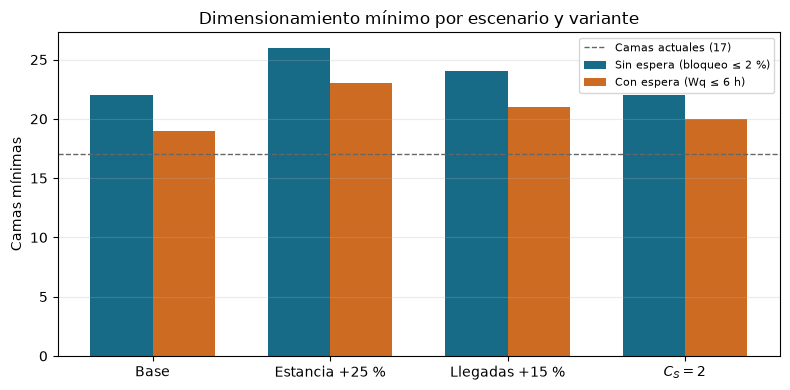

Figura: figuras/task3_robustez.png


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(df_resumen))
w = 0.35
ax.bar(x - w/2, df_resumen['camas_min_sin_espera'], w, label='Sin espera (bloqueo ≤ 2 %)',
       color='#176b87')
ax.bar(x + w/2, df_resumen['camas_min_con_espera'].fillna(0), w, label='Con espera (Wq ≤ 6 h)',
       color='#cd6b23')
ax.axhline(C_ACTUAL, color='0.4', ls='--', lw=1, label='Camas actuales (17)')
ax.set_xticks(x, ['Base', 'Estancia +25 %', 'Llegadas +15 %', r'$C_S=2$'])
ax.set_ylabel('Camas mínimas')
ax.set_title('Dimensionamiento mínimo por escenario y variante')
ax.legend(fontsize=8); ax.grid(axis='y', alpha=.25)
fig.tight_layout()
fig.savefig('figuras/task3_robustez.png', dpi=150)
plt.show()
print('Figura: figuras/task3_robustez.png')


## Parte C — Contingencia por cierre de camas (Task 3.1c)

Configuración principal para **bloqueo**: variante sin espera con $c_{\min}=22$ del caso base (no se mezclan las 19 camas del modelo con espera). Capacidad durante el cierre: $22-6=16$.

**Política de cierre:** no preemptiva. Al reducir capacidad no se dan altas ni traslados ficticios; los pacientes ya hospitalizados terminan su estancia. Mientras `ocupados ≥ capacidad reducida` se bloquean nuevas admisiones. Las salidas liberan cupo hasta la nueva capacidad.

Referencia estacionaria: Erlang B$(16, a=14.4)$. No equivale automáticamente al bloqueo promedio de un cierre transitorio de 7 días: ese valor se obtiene por simulación midiendo solo llegadas en la ventana de cierre.


Camas totales=22, deshabilitadas=6, efectivas=16
Bloqueo base teórico B(22,14.4) = 1.546 %
Referencia estacionaria en cierre B(16,14.4) = 12.641 %
Simulando cierre (30 réplicas)...


IC amplio; añadiendo 30 réplicas más...


Guardado: outputs/task3/task3_cierre.csv


,valor
camas_totales,22
camas_deshabilitadas,6
camas_efectivas,16
bloqueo_base_teorico,0.015456
bloqueo_cierre_teorico_estacionario,0.126412
bloqueo_7d_sim_media,0.125163
bloqueo_7d_IC95_inf,0.090688
bloqueo_7d_IC95_sup,0.159638
bloqueo_7d_semiancho,0.034475
pacientes_desviados_7d_media,3.5


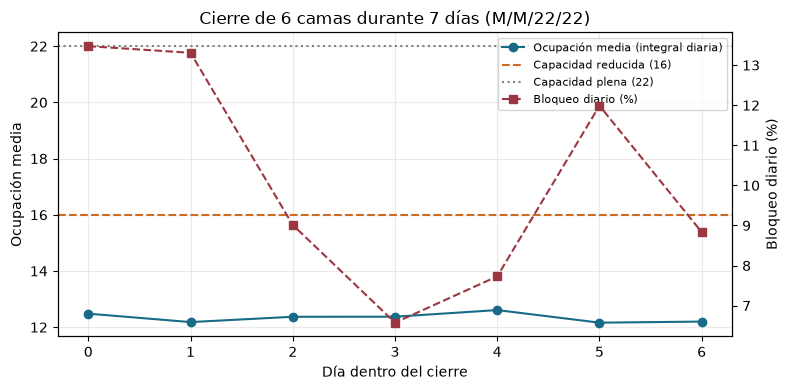

Figura: figuras/task3_cierre.png


In [7]:
c_sin = cB_base  # 22
c_eff = c_sin - K_OFF  # 16
a_base = LAM / MU
B_base = erlang_b(c_sin, a_base)
B_cierre_est = erlang_b(c_eff, a_base)

print(f'Camas totales={c_sin}, deshabilitadas={K_OFF}, efectivas={c_eff}')
print(f'Bloqueo base teórico B({c_sin},{a_base}) = {100*B_base:.3f} %')
print(f'Referencia estacionaria en cierre B({c_eff},{a_base}) = {100*B_cierre_est:.3f} %')

# Simulación: warmup 100, cierre en [300, 307), horizonte suficiente para drenar
t0_c = 300.0
Tb_c = T_CIERRE
horizon_c = 450.0  # deja drenar tras reapertura; métrica de bloqueo solo en [300,307)
warmup_c = 100.0

print('Simulando cierre (30 réplicas)...', flush=True)
rr_cierre = replicas(
    N_REP, MASTER + 9000,
    lam=LAM, mu=MU, c=c_sin, horizon=horizon_c, warmup=warmup_c,
    waiting=False, distribution='exponencial',
    closure=(t0_c, Tb_c, K_OFF), sample_every=1.0,
)
# Control sin cierre (mismas semillas conceptualmente distintas vía master distinto)
rr_ctrl = replicas(
    N_REP, MASTER + 9100,
    lam=LAM, mu=MU, c=c_sin, horizon=horizon_c, warmup=warmup_c,
    waiting=False, distribution='exponencial',
)

xs = [r['prob_block_closure'] for r in rr_cierre]
ic_c = ic95(xs)
# pacientes desviados en 7 días
desv = [r['blocked_closure'] for r in rr_cierre]
ic_desv = ic95(desv)
arr_c = [r['arrivals_closure'] for r in rr_cierre]
ic_arr = ic95(arr_c)

# Bloqueo "normal" en ventana comparable: usar proporciones globales del control
# como referencia de operación normal (estacionaria)
xs_ctrl = [r['prob_block'] for r in rr_ctrl]
ic_ctrl = ic95(xs_ctrl)

# Si IC ancho, subir réplicas
n_extra = 0
if ic_c['semiancho'] > 0.03:
    print('IC amplio; añadiendo 30 réplicas más...', flush=True)
    rr_extra = replicas(
        N_REP, MASTER + 9200,
        lam=LAM, mu=MU, c=c_sin, horizon=horizon_c, warmup=warmup_c,
        waiting=False, distribution='exponencial',
        closure=(t0_c, Tb_c, K_OFF),
    )
    xs = xs + [r['prob_block_closure'] for r in rr_extra]
    desv = desv + [r['blocked_closure'] for r in rr_extra]
    arr_c = arr_c + [r['arrivals_closure'] for r in rr_extra]
    ic_c = ic95(xs)
    ic_desv = ic95(desv)
    ic_arr = ic95(arr_c)
    n_extra = N_REP
    rr_cierre = rr_cierre + rr_extra

tasa_desv = ic_desv['media'] / T_CIERRE  # pac./día durante el cierre
esperados_7d = ic_desv['media']

df_cierre = pd.DataFrame([{
    'camas_totales': c_sin,
    'camas_deshabilitadas': K_OFF,
    'camas_efectivas': c_eff,
    'bloqueo_base_teorico': B_base,
    'bloqueo_cierre_teorico_estacionario': B_cierre_est,
    'bloqueo_7d_sim_media': ic_c['media'],
    'bloqueo_7d_IC95_inf': ic_c['inferior'],
    'bloqueo_7d_IC95_sup': ic_c['superior'],
    'bloqueo_7d_semiancho': ic_c['semiancho'],
    'pacientes_desviados_7d_media': ic_desv['media'],
    'pacientes_desviados_7d_IC95_inf': ic_desv['inferior'],
    'pacientes_desviados_7d_IC95_sup': ic_desv['superior'],
    'llegadas_durante_cierre_media': ic_arr['media'],
    'tasa_desvio_pac_por_dia': tasa_desv,
    'bloqueo_operacion_normal_sim': ic_ctrl['media'],
    'diferencia_bloqueo_pp': 100 * (ic_c['media'] - ic_ctrl['media']),
    'n_replicas': len(xs),
    'politica': 'no preemptiva: no se expulsan ocupantes; se bloquean nuevas admisiones si busy>=capacidad reducida',
}])
df_cierre.to_csv(OUT / 'task3_cierre.csv', index=False)
print('Guardado:', OUT / 'task3_cierre.csv')
display(df_cierre.T.rename(columns={0: 'valor'}))

# Evolución diaria ocupación / bloqueo durante el cierre
dias = list(range(int(T_CIERRE)))
occ_mat, blk_rate = [], []
for r in rr_cierre:
    occ_mat.append([r['daily_occ'].get(d, 0.0) for d in dias])  # integral busy*dt en el día ≈ busy medio si dt~1
    arr = [r['daily_arr'].get(d, 0) for d in dias]
    blk = [r['daily_blk'].get(d, 0) for d in dias]
    blk_rate.append([blk[d] / arr[d] if arr[d] else float('nan') for d in dias])
occ_mat = np.asarray(occ_mat, dtype=float)
# daily_occ es integral de busy en el día (~ busy medio * 1 día)
occ_mean = np.nanmean(occ_mat, axis=0)
blk_mat = np.asarray(blk_rate, dtype=float)
blk_mean = np.nanmean(blk_mat, axis=0)

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(dias, occ_mean, 'o-', color='#176b87', label='Ocupación media (integral diaria)')
ax1.axhline(c_eff, color='#cd6b23', ls='--', label=f'Capacidad reducida ({c_eff})')
ax1.axhline(c_sin, color='0.5', ls=':', label=f'Capacidad plena ({c_sin})')
ax1.set_xlabel('Día dentro del cierre')
ax1.set_ylabel('Ocupación media')
ax2 = ax1.twinx()
ax2.plot(dias, 100 * blk_mean, 's--', color='#9c3742', label='Bloqueo diario (%)')
ax2.set_ylabel('Bloqueo diario (%)')
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8)
ax1.set_title('Cierre de 6 camas durante 7 días (M/M/22/22)')
ax1.grid(alpha=.25)
fig.tight_layout()
fig.savefig('figuras/task3_cierre.png', dpi=150)
plt.show()
print('Figura: figuras/task3_cierre.png')
